In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/playground-series-s4e4/sample_submission.csv
/kaggle/input/competitions/playground-series-s4e4/train.csv
/kaggle/input/competitions/playground-series-s4e4/test.csv
/kaggle/input/datasets/lingululwanishine/playground-series-s4e4/sample_submission.csv
/kaggle/input/datasets/lingululwanishine/playground-series-s4e4/test.csv
/kaggle/input/datasets/lingululwanishine/playground-series-s4e4/train.csv


Using data folder: /kaggle/input/competitions/playground-series-s4e4
Spline model validation RMSLE: 0.16128359239382947


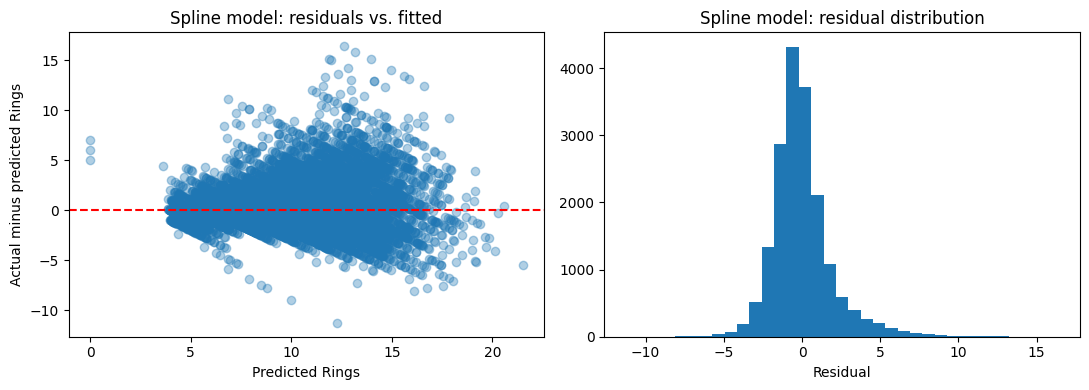

      id      Rings
0  90615   8.378402
1  90616   9.753014
2  90617  10.655531
3  90618  10.419504
4  90619   7.814605
Saved: /kaggle/working/submission_spline.csv


In [2]:
from pathlib import Path
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
 
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_log_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler
 
 
# Find the attached Abalone competition files automatically
data_folders = []
for train_path in Path("/kaggle/input").rglob("train.csv"):
    folder = train_path.parent
    test_path = folder / "test.csv"
 
    if test_path.is_file():
        columns = set(pd.read_csv(train_path, nrows=0).columns)
        if {"id", "Rings"}.issubset(columns):
            data_folders.append(folder)
 
if not data_folders:
    raise FileNotFoundError(
        "Could not find train.csv and test.csv with 'id' and 'Rings' "
        "under /kaggle/input. Attach the competition data using Kaggle's "
        "Add Input panel, then rerun this cell."
    )
 
# Prefer the S4E4 folder if both the competition and dataset copies are attached
data_folders = sorted(
    data_folders,
    key=lambda folder: (
        "s4e4" not in str(folder).lower(),
        str(folder)
    )
)
DATA_DIR = data_folders[0]
print("Using data folder:", DATA_DIR)
 
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
 
target = "Rings"
id_column = "id"
 
X = train.drop(columns=[target, id_column], errors="ignore")
y = train[target]
X_test = test.drop(columns=[id_column], errors="ignore")
 
categorical_columns = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()
numeric_columns = [
    column for column in X.columns
    if column not in categorical_columns
]
 
 
def make_one_hot_encoder():
    # Supports both recent and older scikit-learn versions
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=True)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=True)
 
 
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("splines", SplineTransformer(
            n_knots=5,
            degree=3,
            extrapolation="linear",
            include_bias=False
        )),
        ("scaler", StandardScaler())
    ]), numeric_columns),
 
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", make_one_hot_encoder())
    ]), categorical_columns)
])
 
spline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regression", Ridge(alpha=10.0))
])
 
 
def calculate_rmsle(actual, predicted):
    predicted = np.maximum(predicted, 0)
    return np.sqrt(mean_squared_log_error(actual, predicted))
 
 
# Holdout validation
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=42
)
 
spline_model.fit(X_train, y_train)
valid_predictions = np.maximum(
    spline_model.predict(X_valid), 0
)
 
print(
    "Spline model validation RMSLE:",
    calculate_rmsle(y_valid, valid_predictions)
)
 
# Validation residual diagnostics
residuals = y_valid - valid_predictions
 
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
 
axes[0].scatter(valid_predictions, residuals, alpha=0.35)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(
    xlabel="Predicted Rings",
    ylabel="Actual minus predicted Rings",
    title="Spline model: residuals vs. fitted"
)
 
axes[1].hist(residuals, bins=35)
axes[1].set(
    xlabel="Residual",
    title="Spline model: residual distribution"
)
 
plt.tight_layout()
plt.show()
 
# Refit on all labeled data and create the submission file
spline_model.fit(X, y)
test_predictions = np.maximum(
    spline_model.predict(X_test), 0
)
 
spline_submission = pd.DataFrame({
    id_column: test[id_column],
    target: test_predictions
})
 
output_path = "/kaggle/working/submission_spline.csv"
spline_submission.to_csv(output_path, index=False)
 
print(spline_submission.head())
print("Saved:", output_path)